# ES Futures: Multi-Session OBI and OFI Signal Analysis

**FINM 37000 — From Order Book Imbalance to Executable Alpha**

This notebook evaluates whether top-of-book **order book imbalance (OBI)** and **order flow imbalance (OFI)** predict short-horizon E-mini S&P 500 (ES) futures midprice changes.

**Research design**
- **Instrument:** ES futures, regular trading hours, CME top-of-book data.
- **Research sample:** July 1–August 31, 2026 (43 trading sessions).
- **Model fitting:** First 32 sessions; **validation:** final 11 sessions (August 17–31).
- **Targets:** Forward midprice changes over 1, 5, 10, 30, and 60 seconds, in ES ticks.
- **Models:** OBI, OFI, and OBI + OFI, using simple linear regression.
- **Reserved final test:** September 2026 is **not used** for this analysis.

**Main question:** Does OFI add meaningful predictive information beyond OBI, and does the resulting signal appear economically actionable?

> **Reproducibility:** Run from the repository's configured Python environment. The raw and processed market data are stored locally under `data/` and are not committed to Git. The 43-session processing step is computationally expensive; the resulting one-second panel is saved for reuse.


## 1. Imports and research setup

Use the project's existing data-cleaning, feature-engineering, and OFI research functions rather than duplicating their implementations.


In [ ]:
import gc
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

from finm37000_grp2.config import PROCESSED_DIR, SAMPLES
from finm37000_grp2.data.clean import book_states, read_clean
from finm37000_grp2.features import calculate_obi
from finm37000_grp2.ofi_analysis import (
    chronological_split,
    daily_slopes,
    make_research_frame,
)

## 2. Construct and validate one session

Start with July 1 to confirm the signals align at the **one-second** level. OFI is aggregated from quote updates; OBI is sampled from the last available book state in each second. The forward return is measured from the corresponding second-end midprice.


In [2]:
# Load one trading session
day = "2026-07-01"

df = read_clean(day)
quotes = book_states(df)

# Calculate OFI and forward price movements
panel = make_research_frame(quotes)

# Calculate OBI using the final book state in each second
obi = calculate_obi(quotes["bid_sz"], quotes["ask_sz"])

obi_by_second = (
    pd.DataFrame(
        {
            "obi": obi,
            "second_start_utc": quotes.index.floor("s"),
        }
    )
    .groupby("second_start_utc")["obi"]
    .last()
)

# Align OBI with the OFI panel
panel = panel.merge(
    obi_by_second,
    on="second_start_utc",
    how="left",
)

print(panel.shape)
print(
    panel[["second_start_utc", "obi", "ofi_1s", "fwd_1s_ticks", "fwd_5s_ticks"]].head()
)

(24300, 14)
           second_start_utc       obi  ofi_1s  fwd_1s_ticks  fwd_5s_ticks
0 2026-07-01 13:30:00+00:00 -0.032258    56.0           2.0          -4.0
1 2026-07-01 13:30:01+00:00 -0.294118    22.0           2.0          -8.0
2 2026-07-01 13:30:02+00:00 -0.750000    73.0          -9.0         -11.0
3 2026-07-01 13:30:03+00:00  0.800000  -298.0           5.0         -12.0
4 2026-07-01 13:30:04+00:00 -0.764706   142.0          -4.0         -18.0


### 2.1 Data quality and timestamp checks

Check missing features, the expected OBI range of −1 to +1, and duplicate second timestamps. Missing forward returns near the end of a session are expected because future observations are unavailable.


In [4]:
# Check signal completeness and alignment
print("Missing values:")
print(
    panel[
        [
            "obi",
            "ofi_1s",
            "ofi_5s",
            "fwd_1s_ticks",
            "fwd_5s_ticks",
            "fwd_10s_ticks",
            "fwd_30s_ticks",
            "fwd_60s_ticks",
        ]
    ]
    .isna()
    .sum()
)

print("\nOBI range:")
print(panel["obi"].min(), panel["obi"].max())

print("\nDuplicate timestamps:")
print(panel["second_start_utc"].duplicated().sum())

Missing values:
obi               1
ofi_1s            0
ofi_5s            4
fwd_1s_ticks      1
fwd_5s_ticks      5
fwd_10s_ticks    10
fwd_30s_ticks    30
fwd_60s_ticks    60
dtype: int64

OBI range:
-0.9696969696969697 0.9811320754716981

Duplicate timestamps:
0


## 3. Build the 43-session research panel

Process each trading day separately to limit memory usage. Merge the daily OBI snapshot into the OFI one-second panel, then concatenate the resulting daily panels. This stage can take several minutes.


In [ ]:
sample = SAMPLES["in_sample"]

files = sorted((PROCESSED_DIR / "ES").glob("*.parquet"))
files = [
    f
    for f in files
    if f.stem[:4].isdigit() and sample.start <= date.fromisoformat(f.stem) <= sample.end
]

panels = []

for i, file in enumerate(files, 1):
    day = file.stem

    df = read_clean(day)
    quotes = book_states(df)

    daily_panel = make_research_frame(quotes)

    obi = calculate_obi(quotes["bid_sz"], quotes["ask_sz"])

    obi_by_second = (
        pd.DataFrame(
            {
                "obi": obi,
                "second_start_utc": quotes.index.floor("s"),
            }
        )
        .groupby("second_start_utc")["obi"]
        .last()
    )

    daily_panel = daily_panel.merge(
        obi_by_second,
        on="second_start_utc",
        how="left",
    )

    panels.append(daily_panel)

    del df, quotes, daily_panel, obi, obi_by_second
    gc.collect()

    print(f"[{i}/{len(files)}] Processed {day}", flush=True)

# Combine the one-second panels
all_data = pd.concat(panels, ignore_index=True)

print("\nCombined dataset:", all_data.shape)
print("Sessions:", all_data["session_id"].nunique())

[1/43] Processed 2026-07-01
[2/43] Processed 2026-07-02
[3/43] Processed 2026-07-06
[4/43] Processed 2026-07-07
[5/43] Processed 2026-07-08
[6/43] Processed 2026-07-09
[7/43] Processed 2026-07-10
[8/43] Processed 2026-07-13
[9/43] Processed 2026-07-14
[10/43] Processed 2026-07-15
[11/43] Processed 2026-07-16
[12/43] Processed 2026-07-17
[13/43] Processed 2026-07-20
[14/43] Processed 2026-07-21
[15/43] Processed 2026-07-22
[16/43] Processed 2026-07-23
[17/43] Processed 2026-07-24
[18/43] Processed 2026-07-27
[19/43] Processed 2026-07-28
[20/43] Processed 2026-07-29
[21/43] Processed 2026-07-30
[22/43] Processed 2026-07-31
[23/43] Processed 2026-08-03
[24/43] Processed 2026-08-04
[25/43] Processed 2026-08-05
[26/43] Processed 2026-08-06
[27/43] Processed 2026-08-07
[28/43] Processed 2026-08-10
[29/43] Processed 2026-08-11
[30/43] Processed 2026-08-12
[31/43] Processed 2026-08-13
[32/43] Processed 2026-08-14
[33/43] Processed 2026-08-17
[34/43] Processed 2026-08-18
[35/43] Processed 2026-

### 3.1 Save the processed signal panel

Cache the combined data locally so subsequent analysis does not require rereading millions of event-level quote updates.


In [7]:
output_path = PROCESSED_DIR / "ES" / "in_sample_signals.parquet"

all_data.to_parquet(output_path, index=False)

print("Saved to:", output_path)
print("Dataset shape:", all_data.shape)

Saved to: /Users/kayla/Futures/finm37000-grp-2/data/processed/ES/in_sample_signals.parquet
Dataset shape: (1044900, 14)


### 3.2 Verify that the saved panel can be reloaded

This read-back check confirms that the saved file is usable. **Note:** it does not skip the processing cell above during a full notebook run.


In [2]:
output_path = PROCESSED_DIR / "ES" / "in_sample_signals.parquet"

if output_path.exists():
    all_data = pd.read_parquet(output_path)
    print("Loaded saved dataset:", all_data.shape)
else:
    print("Saved dataset not found.")

Loaded saved dataset: (1044900, 14)


## 4. Chronological training and validation

Split **by trading session**, not by randomly shuffled seconds. The first 32 sessions are used to fit the models; the remaining 11 August sessions are used to evaluate them. September is held back for the project's final out-of-sample backtest.


In [3]:
# Split the 43 in-sample sessions chronologically
train, test = chronological_split(all_data, test_fraction=0.25)

print("Training sessions:", train["session_id"].nunique())
print("Validation sessions:", test["session_id"].nunique())

print("\nTraining period:")
print(train["session_id"].min(), "to", train["session_id"].max())

print("\nValidation period:")
print(test["session_id"].min(), "to", test["session_id"].max())

print("\nObservations:")
print("Training:", len(train))
print("Validation:", len(test))

Training sessions: 32
Validation sessions: 11

Training period:
2026-07-01 to 2026-08-14

Validation period:
2026-08-17 to 2026-08-31

Observations:
Training: 777600
Validation: 267300


## 5. Compare predictive models

All models forecast forward **midprice movement in ticks**, not realized trade P&L. Validation R² measures improvement over a constant-mean benchmark; correlation measures directional co-movement, while MAE measures absolute forecast error.


### Microprice and its relationship to OBI

Microprice is a liquidity-weighted estimate of price based on the best bid, best ask, and their displayed sizes. Under the project's weighted-midprice definition:

**Microprice − Midprice = (Bid-ask spread / 2) × OBI**

Because ES typically has a one-tick spread, microprice displacement and OBI are expected to be strongly related. We first verify this relationship before evaluating whether microprice provides additional predictive information.

In [20]:
# Verify the microprice–OBI relationship on July 1
day_quotes = book_states(read_clean("2026-07-01"))

bid = day_quotes["bid_px"]
ask = day_quotes["ask_px"]
bid_size = day_quotes["bid_sz"]
ask_size = day_quotes["ask_sz"]

midprice = (bid + ask) / 2

microprice = (ask * bid_size + bid * ask_size) / (bid_size + ask_size)

microprice_displacement_ticks = (microprice - midprice) / 0.25

obi = (bid_size - ask_size) / (bid_size + ask_size)
spread_ticks = (ask - bid) / 0.25

expected_displacement = (spread_ticks / 2) * obi

print(
    "Maximum identity error:",
    (microprice_displacement_ticks - expected_displacement).abs().max(),
)
print(
    "Correlation with OBI:",
    microprice_displacement_ticks.corr(obi),
)

Maximum identity error: 1.8157142456232123e-12
Correlation with OBI: 0.9953992919808089


### Microprice–OBI Relationship: Results

The microprice identity holds numerically, with a maximum absolute error of approximately 1.82 × 10⁻¹² ticks.

Microprice displacement and OBI exhibit an extremely strong positive correlation (r = 0.9954) in the July 1 sample.

These findings suggest that microprice displacement contains largely redundant information relative to OBI, consistent with the predominantly one-tick spread observed in ES futures.

Because the two measures are nearly collinear, microprice is unlikely to provide substantial independent predictive information beyond OBI. However, a separate predictive evaluation is still needed to verify their relative performance.

In [22]:
spread_counts = spread_ticks.value_counts(normalize=True).sort_index()

print("Spread distribution (%):")
print((spread_counts * 100).round(3).head(10))

print("\nOne-tick spread frequency:")
print(f"{(spread_ticks == 1).mean():.2%}")

Spread distribution (%):
1.0     95.391
2.0      4.565
3.0      0.033
4.0      0.006
5.0      0.003
6.0      0.001
7.0      0.000
8.0      0.000
9.0      0.000
10.0     0.000
Name: proportion, dtype: float64

One-tick spread frequency:
95.39%


### Interpretation: Microprice Redundancy

On July 1, 95.39% of observed book states have a one-tick bid-ask spread. Consequently, microprice displacement is exactly half of OBI for most observations when expressed in ticks.

This explains the strong correlation between microprice displacement and OBI (r = 0.9954).

Under a constant one-tick spread assumption, microprice displacement is a linear transformation of OBI and therefore provides no additional information to a linear regression model.

**Limitation:** These results are based on July 1 only. The full validation-period microprice performance has not yet been evaluated, and spread variation may introduce differences between the two signals.

### Full-Sample Microprice Evaluation

We extend the July 1 microprice analysis to all 43 research sessions.

Microprice displacement is calculated from the actual best bid, best ask,
and displayed sizes at the end of each second. We compare its predictive
performance with OBI using the same chronological training and validation
sessions.

This tests whether variation in the bid-ask spread provides meaningful
additional predictive information beyond OBI.

In [26]:
# Construct actual microprice displacement for all research sessions
microprice_frames = []

for session in sorted(all_data["session_id"].unique()):
    session_file = PROCESSED_DIR / "ES" / f"{session}.parquet"

    if not session_file.exists():
        print(f"Missing session: {session}")
        continue

    quotes = book_states(read_clean(str(session)))

    bid = quotes["bid_px"]
    ask = quotes["ask_px"]
    bid_size = quotes["bid_sz"]
    ask_size = quotes["ask_sz"]

    mid = (bid + ask) / 2
    microprice = (ask * bid_size + bid * ask_size) / (bid_size + ask_size)

    daily = pd.DataFrame(
        {
            "second_start_utc": quotes.index.floor("s"),
            "microprice_displacement_ticks": (microprice - mid) / 0.25,
        }
    )

    # Use the last observed book state in each second
    daily = daily.groupby("second_start_utc", as_index=False).last()

    daily["session_id"] = session
    microprice_frames.append(daily)

microprice_data = pd.concat(microprice_frames, ignore_index=True)

print("Microprice observations:", microprice_data.shape)
print("Sessions:", microprice_data["session_id"].nunique())

Microprice observations: (1044388, 3)
Sessions: 43


In [27]:
# Merge actual microprice displacement into the research dataset
microprice_comparison = all_data.merge(
    microprice_data,
    on=["session_id", "second_start_utc"],
    how="left",
    validate="one_to_one",
)

print("Original observations:", len(all_data))
print("Merged observations:", len(microprice_comparison))
print(
    "Missing microprice observations:",
    microprice_comparison["microprice_displacement_ticks"].isna().sum(),
)

print(
    "OBI–microprice correlation:",
    microprice_comparison[["obi", "microprice_displacement_ticks"]].corr().iloc[0, 1],
)

Original observations: 1044900
Merged observations: 1044900
Missing microprice observations: 512
OBI–microprice correlation: 0.997432217006969


In [28]:
# Compare OBI, microprice, and their combination
# using the same training and validation observations.

features_to_compare = {
    "OBI": ["obi"],
    "Microprice": ["microprice_displacement_ticks"],
    "OBI + Microprice": ["obi", "microprice_displacement_ticks"],
}

# Preserve the original chronological session split
training_sessions = set(train["session_id"].unique())
validation_sessions = set(test["session_id"].unique())

comparison_train = microprice_comparison[
    microprice_comparison["session_id"].isin(training_sessions)
]
comparison_test = microprice_comparison[
    microprice_comparison["session_id"].isin(validation_sessions)
]

results = []

for horizon in [1, 5, 10, 30, 60]:
    target = f"fwd_{horizon}s_ticks"

    # Same observations for all models
    required = ["obi", "microprice_displacement_ticks", target]

    train_data = comparison_train.dropna(subset=required)
    test_data = comparison_test.dropna(subset=required)

    for name, features in features_to_compare.items():
        model = LinearRegression()
        model.fit(train_data[features], train_data[target])

        predictions = model.predict(test_data[features])

        results.append(
            {
                "horizon": horizon,
                "model": name,
                "r2": r2_score(test_data[target], predictions),
            }
        )

microprice_results = pd.DataFrame(results)

display(
    microprice_results.pivot(
        index="horizon",
        columns="model",
        values="r2",
    ).round(6)
)

model,Microprice,OBI,OBI + Microprice
horizon,,,
1,0.041782,0.042080,0.042178
5,0.009750,0.009855,0.009891
10,0.004665,0.004713,0.004697
30,0.001446,0.001466,0.001480
60,0.000741,0.000750,0.000754


### Full-Sample Microprice Evaluation: Results

Across 43 research sessions, microprice displacement and OBI exhibit an extremely strong correlation (r = 0.9974), indicating substantial overlap in the information captured by these signals.

Using the same chronological training and validation sessions, both features demonstrate nearly identical predictive performance across all five forecast horizons.

At the 1-second horizon, OBI achieves a validation R² of 0.042080, compared with 0.041782 for microprice. Combining OBI and microprice produces an R² of 0.042178, representing only a marginal improvement over OBI alone.

The relationship remains similar at longer horizons, with predictive performance declining substantially for both signals.

**Conclusion:** Microprice provides little incremental predictive information beyond OBI in the current linear models. This is consistent with the near-constant bid-ask spread observed in ES futures and supports prioritizing OBI as the simpler signal for subsequent strategy development.

These results establish predictive similarity, not equivalence under all market conditions or execution strategies.

### 5.1 One-second horizon

Compare OBI alone, OFI alone, and their joint specification. The key incremental-value question is whether **OBI + OFI** improves on **OBI** when evaluated on the same held-out sessions.


In [4]:
target = "fwd_1s_ticks"

models = {
    "OBI": ["obi"],
    "OFI": ["ofi_1s"],
    "OBI + OFI": ["obi", "ofi_1s"],
}

results = []

for name, features in models.items():
    # Keep only observations with valid features and targets
    train_data = train[features + [target]].replace([np.inf, -np.inf], np.nan).dropna()

    test_data = test[features + [target]].replace([np.inf, -np.inf], np.nan).dropna()

    model = LinearRegression()
    model.fit(train_data[features], train_data[target])

    predictions = model.predict(test_data[features])

    results.append(
        {
            "Model": name,
            "Validation R²": r2_score(test_data[target], predictions),
            "Correlation": np.corrcoef(predictions, test_data[target])[0, 1],
            "MAE (ticks)": np.mean(np.abs(test_data[target] - predictions)),
        }
    )

results_df = pd.DataFrame(results)
print(results_df.round(6))

       Model  Validation R²  Correlation  MAE (ticks)
0        OBI       0.042080     0.205189     0.553425
1        OFI       0.000403     0.022274     0.497120
2  OBI + OFI       0.042850     0.207042     0.553553


### 5.2 Signal performance across forecast horizons

Repeat the comparison for 1, 5, 10, 30, and 60 seconds to assess how rapidly predictive power declines. Longer-horizon forward returns overlap across adjacent seconds, so observations should not be treated as independent.


In [5]:
horizons = [1, 5, 10, 30, 60]
horizon_results = []

for h in horizons:
    target = f"fwd_{h}s_ticks"

    for name, features in models.items():
        train_data = (
            train[features + [target]].replace([np.inf, -np.inf], np.nan).dropna()
        )

        test_data = (
            test[features + [target]].replace([np.inf, -np.inf], np.nan).dropna()
        )

        model = LinearRegression()
        model.fit(train_data[features], train_data[target])

        predictions = model.predict(test_data[features])

        horizon_results.append(
            {
                "Horizon (s)": h,
                "Model": name,
                "Validation R²": r2_score(test_data[target], predictions),
                "Correlation": np.corrcoef(predictions, test_data[target])[0, 1],
                "MAE (ticks)": np.mean(np.abs(test_data[target] - predictions)),
            }
        )

horizon_df = pd.DataFrame(horizon_results)

print(
    horizon_df.pivot(
        index="Horizon (s)",
        columns="Model",
        values="Validation R²",
    ).round(6)
)

Model             OBI  OBI + OFI       OFI
Horizon (s)                               
1            0.042080   0.042850  0.000403
5            0.009855   0.009964  0.000031
10           0.004713   0.004749 -0.000035
30           0.001466   0.001472 -0.000112
60           0.000750   0.000753 -0.000234


## 6. Visual evidence

The following figures show three complementary aspects of the signal: **predictive decay**, **directional ordering**, and **stability across trading days**.


### 6.1 Predictive decay: validation R² by horizon

A sharp decline at longer horizons indicates that the relationship is short-lived. A positive R² alone does not imply a profitable execution strategy.


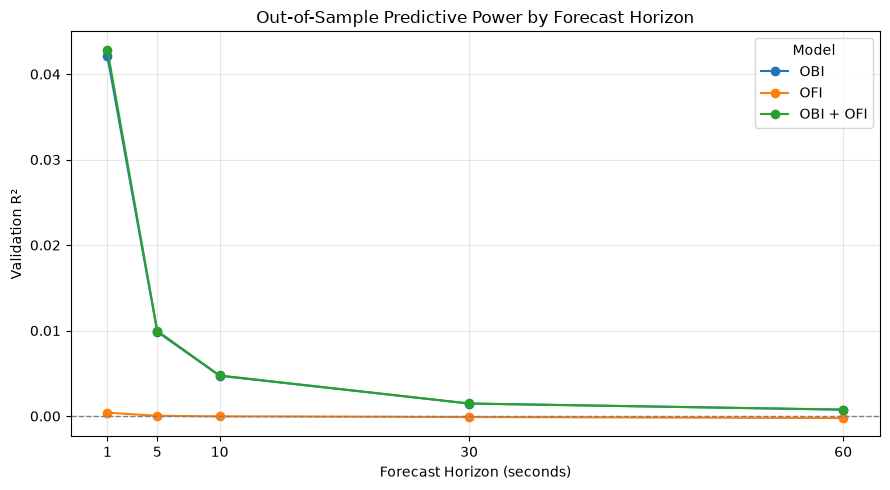

In [6]:
pivot = horizon_df.pivot(
    index="Horizon (s)",
    columns="Model",
    values="Validation R²",
)

ax = pivot[["OBI", "OFI", "OBI + OFI"]].plot(
    marker="o",
    figsize=(9, 5),
)

ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_title("Out-of-Sample Predictive Power by Forecast Horizon")
ax.set_xlabel("Forecast Horizon (seconds)")
ax.set_ylabel("Validation R²")
ax.set_xticks([1, 5, 10, 30, 60])
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 6.2 OBI deciles and next-second returns

Define the decile boundaries using **training data only**, then apply those fixed boundaries to validation observations. A consistent increase in mean forward returns across deciles supports a directional association between OBI and subsequent midprice movement.


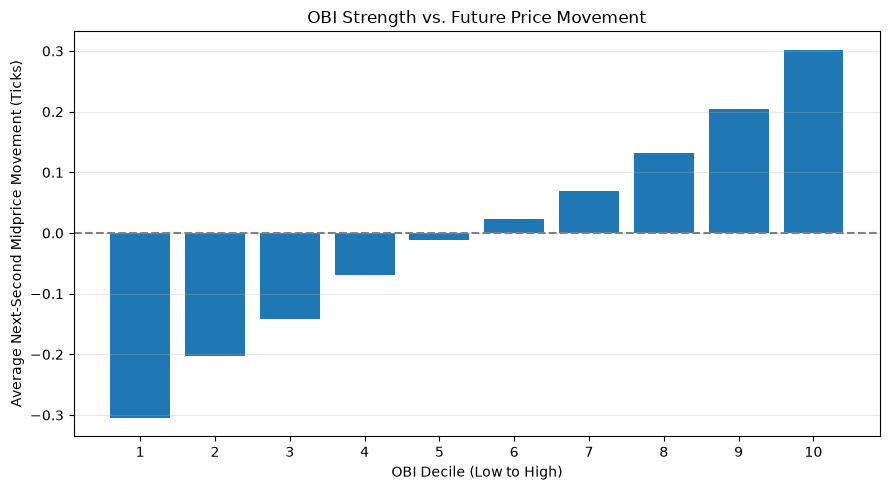

   decile  mean_return  count  mean_obi
0       1      -0.3050  26917   -0.6704
1       2      -0.2019  29423   -0.4421
2       3      -0.1423  28214   -0.2966
3       4      -0.0689  26731   -0.1707
4       5      -0.0110  25118   -0.0514
5       6       0.0224  21654    0.0585
6       7       0.0698  25322    0.1684
7       8       0.1312  28231    0.2936
8       9       0.2048  29173    0.4411
9      10       0.3020  26289    0.6694


In [7]:
# Define OBI deciles using training data only
target = "fwd_1s_ticks"

edges = np.unique(np.quantile(train["obi"].dropna(), np.linspace(0, 1, 11)))
edges[0] = -np.inf
edges[-1] = np.inf

# Apply the same decile boundaries to validation data
decile_data = test[["obi", target]].dropna().copy()

decile_data["decile"] = (
    pd.cut(
        decile_data["obi"],
        bins=edges,
        labels=False,
        include_lowest=True,
    )
    + 1
)

decile_summary = (
    decile_data.groupby("decile")
    .agg(
        mean_return=(target, "mean"),
        count=(target, "size"),
        mean_obi=("obi", "mean"),
    )
    .reset_index()
)

plt.figure(figsize=(9, 5))
plt.bar(decile_summary["decile"], decile_summary["mean_return"])
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("OBI Decile (Low to High)")
plt.ylabel("Average Next-Second Midprice Movement (Ticks)")
plt.title("OBI Strength vs. Future Price Movement")
plt.xticks(decile_summary["decile"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(decile_summary.round(4))

### 6.2.1 Signal Strength Across Forecast Horizons

We compare conditional forward midprice returns across OBI and OFI
deciles at 1, 5, 10, 30, and 60-second horizons.

Decile boundaries are estimated using training data only and applied
to held-out validation sessions to avoid look-ahead bias.

A monotonic relationship between signal strength and future returns
indicates that stronger signals are associated with larger subsequent
price movements.

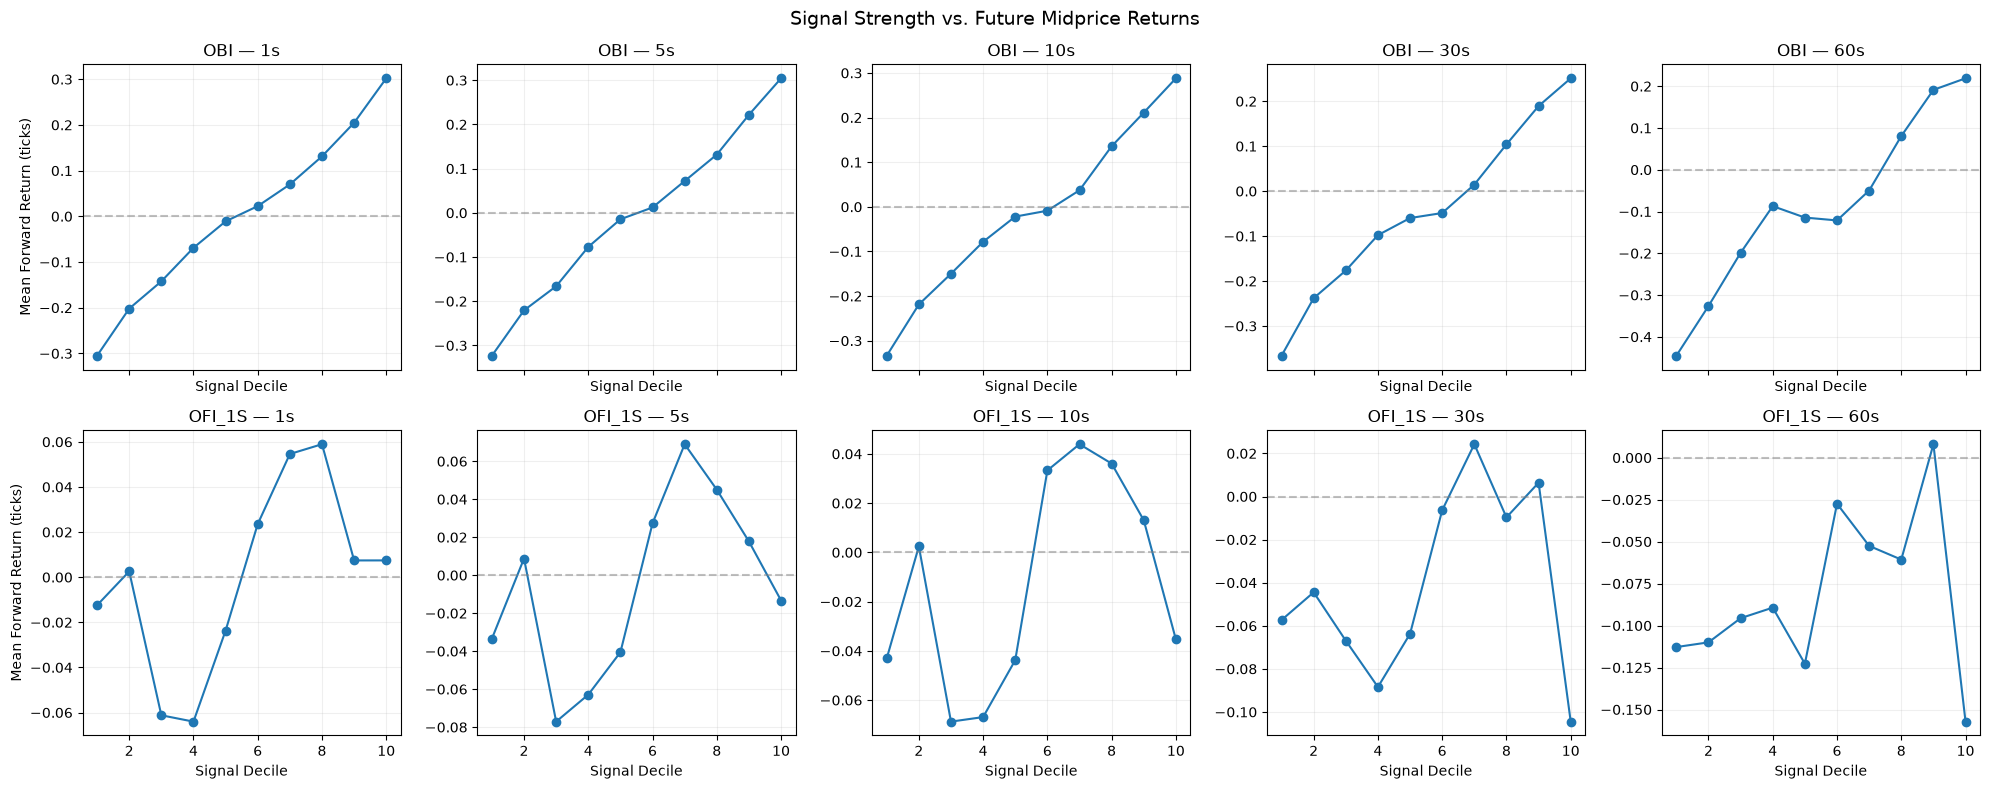

In [25]:
# Compare OBI and OFI deciles across forecast horizons
horizons = [1, 5, 10, 30, 60]
signals = ["obi", "ofi_1s"]

fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True)

for row, signal in enumerate(signals):
    # Training-only decile boundaries
    train_values = train[signal].dropna()
    _, bins = pd.qcut(
        train_values,
        q=10,
        retbins=True,
        duplicates="drop",
    )

    # Include validation observations outside training range
    bins[0] = -np.inf
    bins[-1] = np.inf

    for col, horizon in enumerate(horizons):
        target = f"fwd_{horizon}s_ticks"

        subset = test[[signal, target]].dropna().copy()
        subset["decile"] = pd.cut(
            subset[signal],
            bins=bins,
            labels=False,
            include_lowest=True,
        )

        summary = subset.groupby("decile")[target].mean()

        ax = axes[row, col]
        ax.plot(
            summary.index + 1,
            summary.values,
            marker="o",
        )
        ax.axhline(0, color="gray", linestyle="--", alpha=0.5)

        ax.set_title(f"{signal.upper()} — {horizon}s")
        ax.set_xlabel("Signal Decile")
        ax.grid(alpha=0.2)

        if col == 0:
            ax.set_ylabel("Mean Forward Return (ticks)")

plt.suptitle(
    "Signal Strength vs. Future Midprice Returns",
    fontsize=14,
)
plt.tight_layout()
plt.show()

### Signal Strength Across Horizons: Results

OBI demonstrates a clear positive relationship between signal strength and subsequent midprice returns across the five evaluated horizons (1, 5, 10, 30, and 60 seconds).

The relationship is most consistently monotonic at shorter horizons. At 30 and 60 seconds, the decile patterns become less smooth, although stronger positive OBI values generally remain associated with higher average forward returns.

In contrast, OFI exhibits substantially less consistent conditional return patterns. Its decile-level returns fluctuate rather than increasing monotonically with signal strength, supporting the earlier finding that OFI provides comparatively weak standalone predictive information.

Although OBI maintains directional ordering at longer horizons, its declining validation R² indicates that this relationship explains a progressively smaller share of individual price movements.

These findings reinforce OBI as the stronger signal in the current analysis, while highlighting the distinction between statistical predictability and economically executable trading opportunities.

### 6.3 Prediction Calibration

This analysis evaluates whether the OBI model's predicted next-second
midprice movements correspond to realized returns.

Predictions are generated using a model fitted on training sessions.
Validation predictions are grouped into bins, and average predicted
returns are compared with average realized returns.

Points near the 45-degree reference line indicate better calibration.

,mean_predicted,mean_realized,count
0,-0.309145,-0.304811,26728
1,-0.207134,-0.207479,26687
2,-0.143803,-0.148733,26709
3,-0.087195,-0.079171,26708
4,-0.027370,-0.017280,29571
5,0.030537,0.024457,23899
6,0.085310,0.075910,26729
7,0.143111,0.136122,26737
8,0.207162,0.210187,26631
9,0.309515,0.300697,26673


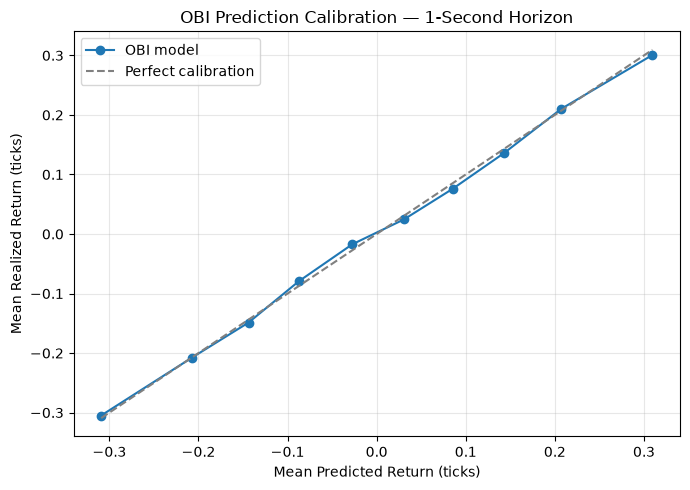

In [23]:
# Fit OBI model on training data
features = ["obi"]
target = "fwd_1s_ticks"

train_clean = train.dropna(subset=features + [target])
test_clean = test.dropna(subset=features + [target])

model = LinearRegression()
model.fit(train_clean[features], train_clean[target])

# Generate held-out predictions
calibration = test_clean[[target]].copy()
calibration["predicted"] = model.predict(test_clean[features])

# Group predictions into 10 bins
calibration["bin"] = pd.qcut(
    calibration["predicted"],
    q=10,
    duplicates="drop",
)

calibration_summary = (
    calibration.groupby("bin", observed=True)
    .agg(
        mean_predicted=("predicted", "mean"),
        mean_realized=(target, "mean"),
        count=(target, "size"),
    )
    .reset_index(drop=True)
)

display(calibration_summary)

# Plot predicted vs. realized returns
plt.figure(figsize=(7, 5))

plt.plot(
    calibration_summary["mean_predicted"],
    calibration_summary["mean_realized"],
    marker="o",
    label="OBI model",
)

limits = [
    min(
        calibration_summary["mean_predicted"].min(),
        calibration_summary["mean_realized"].min(),
    ),
    max(
        calibration_summary["mean_predicted"].max(),
        calibration_summary["mean_realized"].max(),
    ),
]

plt.plot(limits, limits, "--", color="gray", label="Perfect calibration")

plt.xlabel("Mean Predicted Return (ticks)")
plt.ylabel("Mean Realized Return (ticks)")
plt.title("OBI Prediction Calibration — 1-Second Horizon")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Calibration Results and Interpretation

The OBI model demonstrates strong aggregate calibration at the 1-second horizon. Across ten prediction bins, mean realized midprice returns closely track mean predicted returns, with observations lying near the 45-degree reference line.

For example, the highest prediction bin has an average predicted return of +0.310 ticks and an average realized return of +0.301 ticks. The lowest bin predicts approximately −0.309 ticks and realizes −0.305 ticks.

These results suggest that the model captures the average magnitude and direction of short-horizon price movements reasonably well across different signal strengths.

However, good aggregate calibration does not imply accurate individual predictions or profitable trading. The model's validation R² remains approximately 0.042, and execution costs must still be considered.

## 7. Economic relevance: spread versus predicted movement

A short-horizon midprice prediction must be interpreted alongside the cost of entering and exiting a position. This diagnostic measures the **July 1** quoted spread at the event level; it is an illustrative check, **not** a complete validation-period cost estimate or an executable backtest.


In [8]:
# Reload July 1 book states
df = read_clean("2026-07-01")
quotes = book_states(df)

# Calculate the bid-ask spread in ES ticks
spread_ticks = (quotes["ask_px"] - quotes["bid_px"]) / 0.25

print("Average spread (ticks):", spread_ticks.mean())
print("Median spread (ticks):", spread_ticks.median())
print("Percentage with 1-tick spread:", (spread_ticks == 1).mean() * 100)

Average spread (ticks): 1.0467399580628876
Median spread (ticks): 1.0
Percentage with 1-tick spread: 95.39139334009543


### 7.1 Signal Power Relative to the Spread

We measure the proportion of validation predictions whose absolute
magnitude exceeds a one-tick bid-ask spread.

A one-tick threshold approximates the round-trip spread cost of
entering and exiting with market orders, excluding fees and slippage.

This provides a preliminary measure of whether the predicted
price movements are large enough to potentially cover execution costs.

Validation observations: 267,072
Mean absolute predicted return: 0.1550 ticks
Maximum absolute predicted return: 0.4552 ticks
Fraction exceeding 1-tick spread: 0.0000%


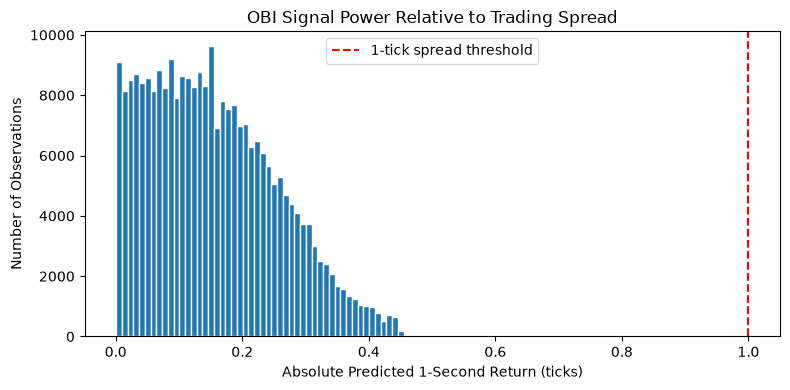

In [24]:
# Fraction of OBI predictions exceeding the assumed spread
spread_threshold = 1.0  # ES ticks

absolute_predictions = calibration["predicted"].abs()

power = (absolute_predictions > spread_threshold).mean()

print(f"Validation observations: {len(calibration):,}")
print(f"Mean absolute predicted return: {absolute_predictions.mean():.4f} ticks")
print(f"Maximum absolute predicted return: {absolute_predictions.max():.4f} ticks")
print(f"Fraction exceeding 1-tick spread: {power:.4%}")

# Show the distribution of predicted return magnitudes
plt.figure(figsize=(8, 4))
plt.hist(absolute_predictions, bins=50, edgecolor="white")
plt.axvline(
    spread_threshold,
    color="red",
    linestyle="--",
    label="1-tick spread threshold",
)

plt.xlabel("Absolute Predicted 1-Second Return (ticks)")
plt.ylabel("Number of Observations")
plt.title("OBI Signal Power Relative to Trading Spread")
plt.legend()
plt.tight_layout()
plt.show()

### 7.2 Signal Power: Results and Interpretation

Across 267,072 held-out validation observations, the OBI model produces a mean absolute predicted 1-second midprice movement of 0.1550 ticks and a maximum absolute prediction of 0.4552 ticks.

**No predictions exceed the assumed one-tick spread threshold (0.00%).**

Although OBI demonstrates measurable predictive power and strong aggregate calibration, its predicted short-horizon movements are insufficient to overcome the assumed round-trip spread cost of aggressive market-order execution.

This distinction highlights the difference between statistical predictability and economically executable alpha.

**Limitations:** The analysis assumes a fixed one-tick spread and does not incorporate actual validation-period spreads, commissions, slippage, market impact, or passive limit-order execution. The result therefore does not establish that all OBI-based trading strategies would be unprofitable.

## 8. Stability across validation sessions

Estimate a separate OBI-to-next-second-return slope for each of the 11 validation days. Consistently positive slopes provide evidence that the relationship is not confined to one unusual session, although they do not establish independence or tradability.


In [9]:
daily_results = daily_slopes(
    test,
    signal="obi",
    target="fwd_1s_ticks",
)

print(daily_results.round(4))
print("\nColumns:", daily_results.columns.tolist())

    session_id   slope      n
0   2026-08-17  0.4201  24274
1   2026-08-18  0.4390  24285
2   2026-08-19  0.4726  24283
3   2026-08-20  0.4966  24294
4   2026-08-21  0.4496  24270
5   2026-08-24  0.4325  24292
6   2026-08-25  0.4667  24259
7   2026-08-26  0.4183  24257
8   2026-08-27  0.4503  24282
9   2026-08-28  0.4667  24291
10  2026-08-31  0.4569  24285

Columns: ['session_id', 'slope', 'n']


### 8.1 Daily slope summary

Summarize the mean, variation, and number of positive daily slopes.


In [10]:
print("Mean daily slope:", round(daily_results["slope"].mean(), 4))
print("Std. deviation:", round(daily_results["slope"].std(), 4))
print("Positive days:", (daily_results["slope"] > 0).sum())
print("Total days:", len(daily_results))

Mean daily slope: 0.4518
Std. deviation: 0.0236
Positive days: 11
Total days: 11


### 8.2 Daily stability visualization

The dashed horizontal line shows the mean daily slope; the zero line indicates the absence of a positive linear relationship.


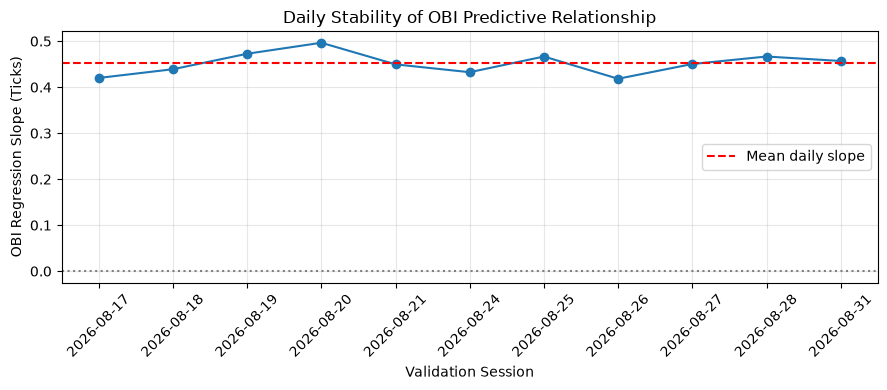

In [11]:
plt.figure(figsize=(9, 4))

plt.plot(
    daily_results["session_id"],
    daily_results["slope"],
    marker="o",
)

plt.axhline(
    daily_results["slope"].mean(),
    color="red",
    linestyle="--",
    label="Mean daily slope",
)

plt.axhline(0, color="gray", linestyle=":")

plt.title("Daily Stability of OBI Predictive Relationship")
plt.xlabel("Validation Session")
plt.ylabel("OBI Regression Slope (Ticks)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Key Findings and Limitations

### Key Findings

1. **OBI is the strongest individual predictor.** At the 1-second horizon, OBI achieves a validation R² of 0.0421, compared with 0.0004 for OFI and 0.0418 for microprice.

2. **Predictive power decays rapidly.** OBI's validation R² decreases from 0.0421 at 1 second to 0.0099 at 5 seconds and approximately 0.0008 at 60 seconds.

3. **Combining signals offers limited improvement.** Adding OFI or microprice to OBI produces only marginal gains in validation R², suggesting substantial redundancy or limited incremental predictive information.

4. **OBI exhibits consistent directional ordering.** Average future midprice returns generally increase across OBI deciles at all five horizons, with the strongest monotonic patterns at shorter horizons. OFI displays less consistent conditional return patterns.

5. **OBI is stable across validation sessions.** The 1-second OBI regression slope is positive across all 11 held-out August sessions, with a mean of 0.4518 and standard deviation of 0.0236.

6. **OBI predictions are well-calibrated on average.** Mean predicted and realized 1-second returns align closely across ten validation prediction bins. However, the model explains only approximately 4.2% of individual return variation.

7. **Microprice provides little incremental information.** Microprice displacement and OBI have a correlation of 0.9974 across the research sample. Their predictive performance is nearly identical, consistent with the predominantly one-tick ES spread.

8. **Statistical predictability does not translate directly into executable alpha.** Across 267,072 validation observations, the maximum absolute predicted 1-second movement is 0.4552 ticks. No predictions exceed the assumed one-tick spread threshold.

### Limitations

- **Execution costs:** The signal-power calculation assumes a fixed one-tick round-trip spread cost and excludes commissions, slippage, market impact, and passive execution.
- **Microprice